# 01. Разбираемся в продажах и остатках

Цель этого ноутбука — понять, что означает строка каждой таблицы, как таблицы связаны и какие ограничения есть у данных. Исследуем все строки; только точечный график строим по случайной выборке. EDA — исследовательский анализ данных: здесь мы проверяем факты до создания признаков и обучения.

## Основные сущности

| Сущность | Поля в файлах | Что означает |
|---|---|---|
| Товар | `article` | Анонимный артикул. Обозначает товар, а не строку продажи. |
| Описание товара | `category_lvl_1/2/3`, `characteristic` | Три уровня товарной категории и характеристика. В этих файлах каждому артикулу соответствует одно описание. |
| Склад | `warehouse_name` | Место, по которому есть остатки и продажи. Один товар встречается на разных складах. |
| География и организация | `cities_name`, `composite_division` | Город и подразделение строки продажи. У одного склада бывает несколько городов и подразделений; это не взаимозаменяемые поля. |
| Продажа | Дата, товар, склад, количество и денежные поля | Исходная строка учёта продаж. Без описания источника не считаем её отдельным чеком или заказом. |
| Остаток | Дата, товар, склад, `stock` | Записанное значение остатка. На один день, склад и товар бывает несколько разных значений. |

## Как таблицы связываются

Общий ключ — **дата × склад × артикул**. Дата связывает наблюдения во времени, склад и артикул задают товарную пару. Несколько строк продаж на этом ключе суммируем по `quantity`. Несколько остатков на том же ключе не складываем вслепую: сначала изучаем повторы.

Например, для «склад 0 × артикул 119» за определённую дату могут существовать несколько продаж и несколько записей остатка. Прямое объединение исходных строк размножит записи. Поэтому перед объединением получаем по одной строке на дневной ключ.

## От сущностей к признакам

**Признак** — информация, доступная модели до прогноза. Склад и товар дают исходные категории; дата даёт календарь; последовательность прошлых продаж пары даёт лаги и средние; остатки дают информацию о наличии. Сочетание «товар × день недели» позволяет описывать разные недельные привычки товаров. Всё это позже описано в [словаре признаков](../features/FEATURES.md).

**Цель** — количество продаж за будущий день на паре склад × артикул. Оно не является входным признаком. До получения официальной постановки рассматриваем прогноз на один день вперёд.

Короткие имена полей в коде оставлены для воспроизводимости; подписи таблиц и графиков — на русском. PNG и небольшие таблицы сохраняются в `data/artifacts/research/`.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'docs/datasets').is_dir())

import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from features.catalog import LABELS, GROUP_LABELS, MODEL_LABELS, feature_label, identifier_label, display_ru
plt.rcParams.update({'date.autoformatter.month':'%m.%Y','date.autoformatter.day':'%d.%m',
                     'date.autoformatter.year':'%Y'})

RAW = ROOT / 'docs/datasets'
PROCESSED = ROOT / 'data/processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option('display.max_columns', 80)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

OUT = ROOT / 'data/artifacts/research'
OUT.mkdir(parents=True, exist_ok=True)
def savefig(name):
    plt.savefig(OUT / name, dpi=160, bbox_inches='tight')
    plt.show()
CAT = ['composite_division','cities_name','warehouse_name','category_lvl_1','category_lvl_2','category_lvl_3','article','characteristic']
sales = pd.read_csv(RAW / 'sales_dataset_hakaton_train.csv', parse_dates=['date'], dtype={c:'category' for c in CAT})
stock = pd.read_csv(RAW / 'stock_dataset_hakaton_train.csv', parse_dates=['date'], dtype={'warehouse_name':'category','article':'category'})
for name, df in [('sales', sales), ('stock', stock)]:
    print(f'{"Продажи" if name=="sales" else "Остатки"}: {len(df):,} строк, {df.shape[1]} столбцов, {df.memory_usage(deep=True).sum()/2**20:.1f} MiB в памяти')
    display_ru(df.head(3))

Продажи: 1,492,370 строк, 12 столбцов, 59.8 MiB в памяти


,Дата,Подразделение,Город,Склад,Категория 1-го уровня,Категория 2-го уровня,Категория 3-го уровня,Артикул,Характеристика товара,Количество продаж,Сумма продаж: исходная шкала,Скидка: исходная шкала
0,2024-01-01,Подразделение = 0,Город = 0,Склад = 0,Категория 1-го уровня = 0,Категория 2-го уровня = 0,NaN,Артикул 0,Характеристика товара = 0,2.0,7.429034,5.459302
1,2024-01-01,Подразделение = 0,Город = 0,Склад = 0,Категория 1-го уровня = 1,Категория 2-го уровня = 1,NaN,Артикул 1,Характеристика товара = 0,1.0,9.613652,7.798864
2,2024-01-01,Подразделение = 0,Город = 0,Склад = 0,Категория 1-го уровня = 2,Категория 2-го уровня = 2,NaN,Артикул 2,Характеристика товара = 0,1.0,9.237081,7.258904


Остатки: 6,153,988 строк, 4 столбцов, 111.6 MiB в памяти


,Дата,Склад,Артикул,Остаток
0,2023-12-13,Склад = 0,Артикул 119,1
1,2023-12-13,Склад = 3,Артикул 62,135
2,2023-12-13,Склад = 3,Артикул 268,3


## Схема и пропуски

`quantity` — количество в строке продаж. Одна строка пока не равна спросу склада за день. Денежные поля исследуем в исходной шкале: название столбца не доказывает, что значение выражено в рублях.

In [2]:
profiles = []
for name, df in [('sales', sales), ('stock', stock)]:
    p = pd.DataFrame({'dtype':df.dtypes.astype(str), 'unique':df.nunique(), 'missing':df.isna().sum(), 'missing_pct':100*df.isna().mean()})
    p.index.name = 'column'
    p.insert(0, 'table', name)
    profiles.append(p.reset_index())
    display_ru(p.round(3))
profile = pd.concat(profiles, ignore_index=True)
profile.to_csv(OUT / 'column_profile.csv', index=False)
num_profiles=[]
for name, df in [('sales',sales),('stock',stock)]:
    p=df.select_dtypes('number').describe(percentiles=[.01,.05,.5,.9,.95,.99,.999]).T
    p['zero_pct']=100*df[p.index].eq(0).mean()
    p['negative_pct']=100*df[p.index].lt(0).mean()
    p.insert(0,'table',name)
    display_ru(p.round(4))
    num_profiles.append(p.rename_axis('column').reset_index())
pd.concat(num_profiles).to_csv(OUT/'numeric_profile.csv',index=False)

,Таблица,Тип в Python,Разных значений,Пропусков,"Пропусков, %"
Столбец,,,,,
Дата,Продажи,datetime64[us],943,0,0.000
Подразделение,Продажи,category,16,0,0.000
Город,Продажи,category,209,0,0.000
Склад,Продажи,category,11,0,0.000
Категория 1-го уровня,Продажи,category,14,0,0.000
Категория 2-го уровня,Продажи,category,51,0,0.000
Категория 3-го уровня,Продажи,category,1,1491432,99.937
Артикул,Продажи,category,799,0,0.000
Характеристика товара,Продажи,category,61,0,0.000


,Таблица,Тип в Python,Разных значений,Пропусков,"Пропусков, %"
Столбец,,,,,
Дата,Остаток,datetime64[us],962,0,0.0
Склад,Остаток,category,11,0,0.0
Артикул,Остаток,category,799,0,0.0
Остаток,Остаток,int64,884,0,0.0


,Таблица,Число значений,Среднее,Стандартное отклонение,Минимум,1%,5%,50%,90%,95%,99%,99.9%,Максимум,"Нулей, %","Отрицательных, %"
Количество продаж,Продажи,1492370.0,1.2241,0.7942,1.0000,1.0000,1.0000,1.0000,2.0000,2.0000,4.0000,8.0000,200.0000,0.0,0.0000
Сумма продаж: исходная шкала,Продажи,1492367.0,8.7632,0.8738,-0.1341,6.4095,7.0794,8.8639,9.7150,9.9835,10.5384,11.1677,13.2146,0.0,0.0399
Скидка: исходная шкала,Продажи,1175415.0,2.9625,3.5249,-5.8630,-0.0929,-0.0585,0.0489,7.7543,8.2140,10.4875,11.4932,13.1217,0.0,22.2928


,Таблица,Число значений,Среднее,Стандартное отклонение,Минимум,1%,5%,50%,90%,95%,99%,99.9%,Максимум,"Нулей, %","Отрицательных, %"
Остаток,Остаток,6153988.0,6.1806,23.0363,-2.0,0.0,0.0,0.0,15.0,29.0,99.0,287.0,1375.0,62.7638,0.0009


## Повторяющиеся ключи и справочники

Проверяем ключ `date × warehouse_name × article`. Продажи по нему суммируем. Для остатков отдельно считаем полные дубликаты и ключи с разными значениями. Без описания источника нельзя узнать, являются ли повторы отдельными запасами или снимками одного запаса.

In [3]:
KEY=['date','warehouse_name','article']
stock_daily=(stock.groupby(KEY,observed=True,sort=False).stock
             .agg(stock_mean='mean',stock_min='min',stock_max='max',stock_records='size').reset_index())
sales_daily=(sales.groupby(KEY,observed=True,sort=False).quantity.sum().rename('quantity').reset_index())
quality=[]
for name,df in [('sales',sales),('stock',stock)]:
    quality.append({'table':name,'rows':len(df),'dates':df.date.nunique(),
                    'date_min':str(df.date.min().date()),'date_max':str(df.date.max().date()),
                    'exact_duplicate_rows':int(df.duplicated().sum()),
                    'extra_rows_over_daily_key':int(df.duplicated(KEY).sum())})
quality=pd.DataFrame(quality)
display_ru(quality)
quality.to_csv(OUT/'table_profile.csv',index=False)
conflicts=stock_daily.stock_min.ne(stock_daily.stock_max)
conflict_summary={'daily_stock_keys':len(stock_daily),'repeated_keys':int(stock_daily.stock_records.gt(1).sum()),
                  'conflicting_keys':int(conflicts.sum()),'conflicting_pct':float(100*conflicts.mean())}
display_ru(pd.Series(conflict_summary,name='value').to_frame())
display_ru(stock_daily.loc[conflicts].head(5))
attrs=['category_lvl_1','category_lvl_2','category_lvl_3','characteristic']
article_mapping=sales.groupby('article',observed=True)[attrs].nunique()
display_ru(article_mapping.max().rename('max_values_per_article').to_frame())
warehouse_mapping=sales.groupby('warehouse_name',observed=True)[['cities_name','composite_division']].nunique()
display_ru(warehouse_mapping)
stock_daily.to_parquet(PROCESSED/'stock_daily.parquet',index=False)
sales_daily.to_parquet(PROCESSED/'sales_daily.parquet',index=False)
# Метаданные артикула доступны с первой наблюдаемой продажи; FE учитывает эту дату.
article_meta=sales.sort_values('date').drop_duplicates('article')[['article','date',*attrs]].rename(columns={'date':'metadata_available_from'})
article_meta.to_parquet(PROCESSED/'article_metadata.parquet',index=False)

,Таблица,Число строк,Дней,Первая дата,Последняя дата,Полных дубликатов строк,Лишних строк на дневном ключе
0,Продажи,1492370,943,2024-01-01,2026-07-31,0,521693
1,Остаток,6153988,962,2023-12-13,2026-07-31,427990,1269790


,Значение
Дневных ключей остатков,4.884198e+06
Ключей с повторами,1.039305e+06
Ключей с разными остатками,8.045880e+05
"Таких ключей, %",1.647329e+01


,Дата,Склад,Артикул,Средний остаток на дневном ключе,Минимальный остаток на ключе,Максимальный остаток на ключе,Число записей остатка на ключе
51214,2024-01-17,Склад = 2,Артикул 170,8.5,1,16,2
51299,2024-01-17,Склад = 2,Артикул 72,3.0,1,5,2
51351,2024-01-17,Склад = 2,Артикул 231,4.0,1,7,2
51352,2024-01-17,Склад = 2,Артикул 85,11.0,2,20,2
51375,2024-01-17,Склад = 2,Артикул 94,41.0,5,77,2


,Максимум значений на артикул
Категория 1-го уровня,1
Категория 2-го уровня,1
Категория 3-го уровня,1
Характеристика товара,1


,Город,Подразделение
Склад,,
Склад = 0,3,10
Склад = 1,17,11
Склад = 2,80,16
Склад = 3,19,16
Склад = 4,9,13
Склад = 5,11,12
Склад = 6,13,12
Склад = 7,14,12
Склад = 8,8,11


## Числовые распределения: центр и хвост

Слева показан весь диапазон; справа — значения между 1-м и 99-м перцентилями. Это только ограничение оси графика, строки из расчётов не удаляются. Логарифмическая ось частот помогает увидеть редкие большие значения.

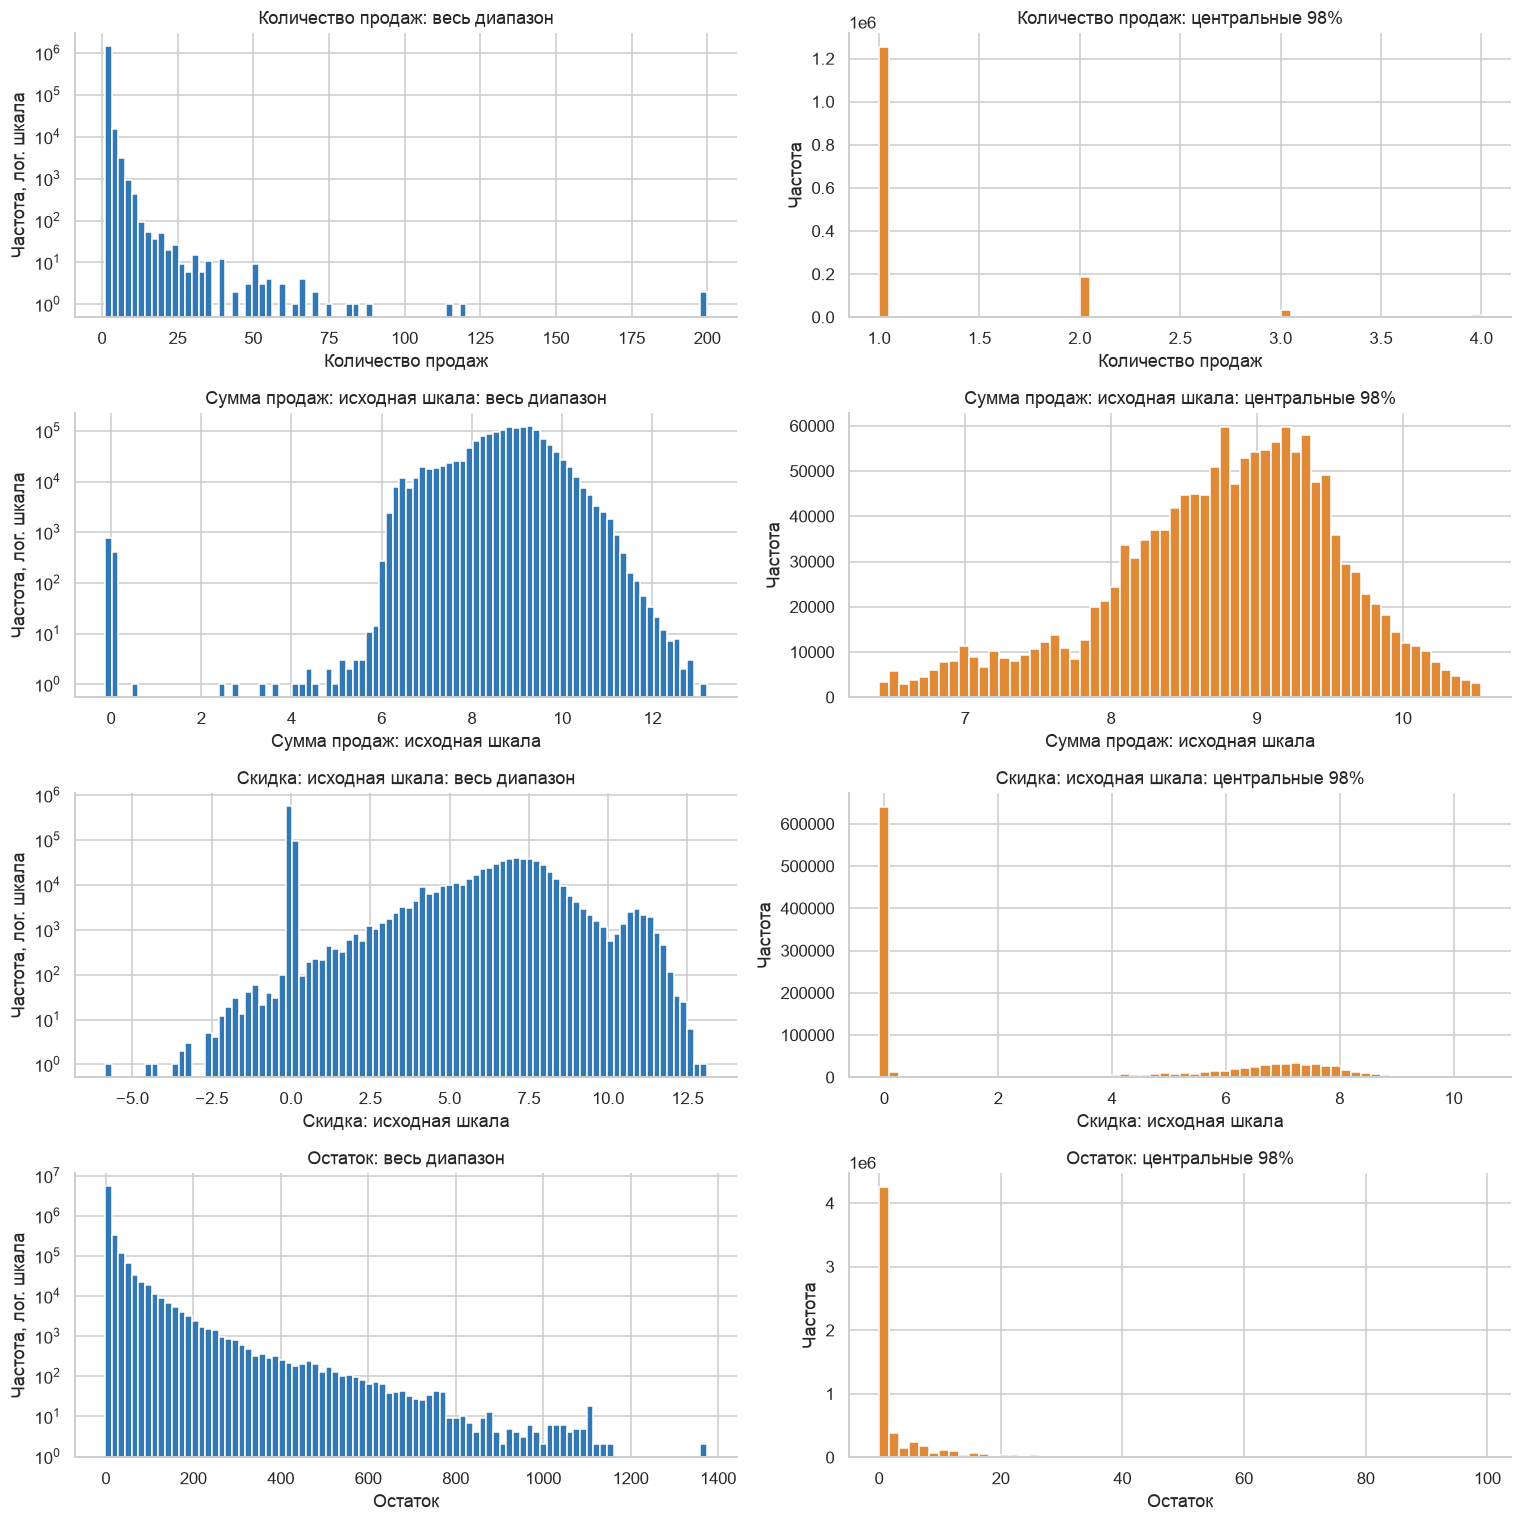

In [4]:
fields=[('sales','quantity',sales),('sales','sales_sum',sales),('sales','discount_sum',sales),('stock','stock',stock)]
fig,axes=plt.subplots(len(fields),2,figsize=(14,14))
for row,(table,col,df) in enumerate(fields):
    x=df[col].dropna()
    axes[row,0].hist(x,bins=90,color='#3178b5',log=True)
    axes[row,0].set(title=f'{feature_label(col)}: весь диапазон',xlabel=feature_label(col),ylabel='Частота, лог. шкала')
    low,high=x.quantile([.01,.99])
    axes[row,1].hist(x[x.between(low,high)],bins=60,color='#e08a37')
    axes[row,1].set(title=f'{feature_label(col)}: центральные 98%',xlabel=feature_label(col),ylabel='Частота')
plt.tight_layout(); savefig('01_numeric_distributions.png')

## Частоты категорий

У каждой категории показаны 12 самых частых значений; остальные объединены в «Остальные». Пропуск — отдельное значение. Число после имени в анонимном идентификаторе не имеет числового смысла.

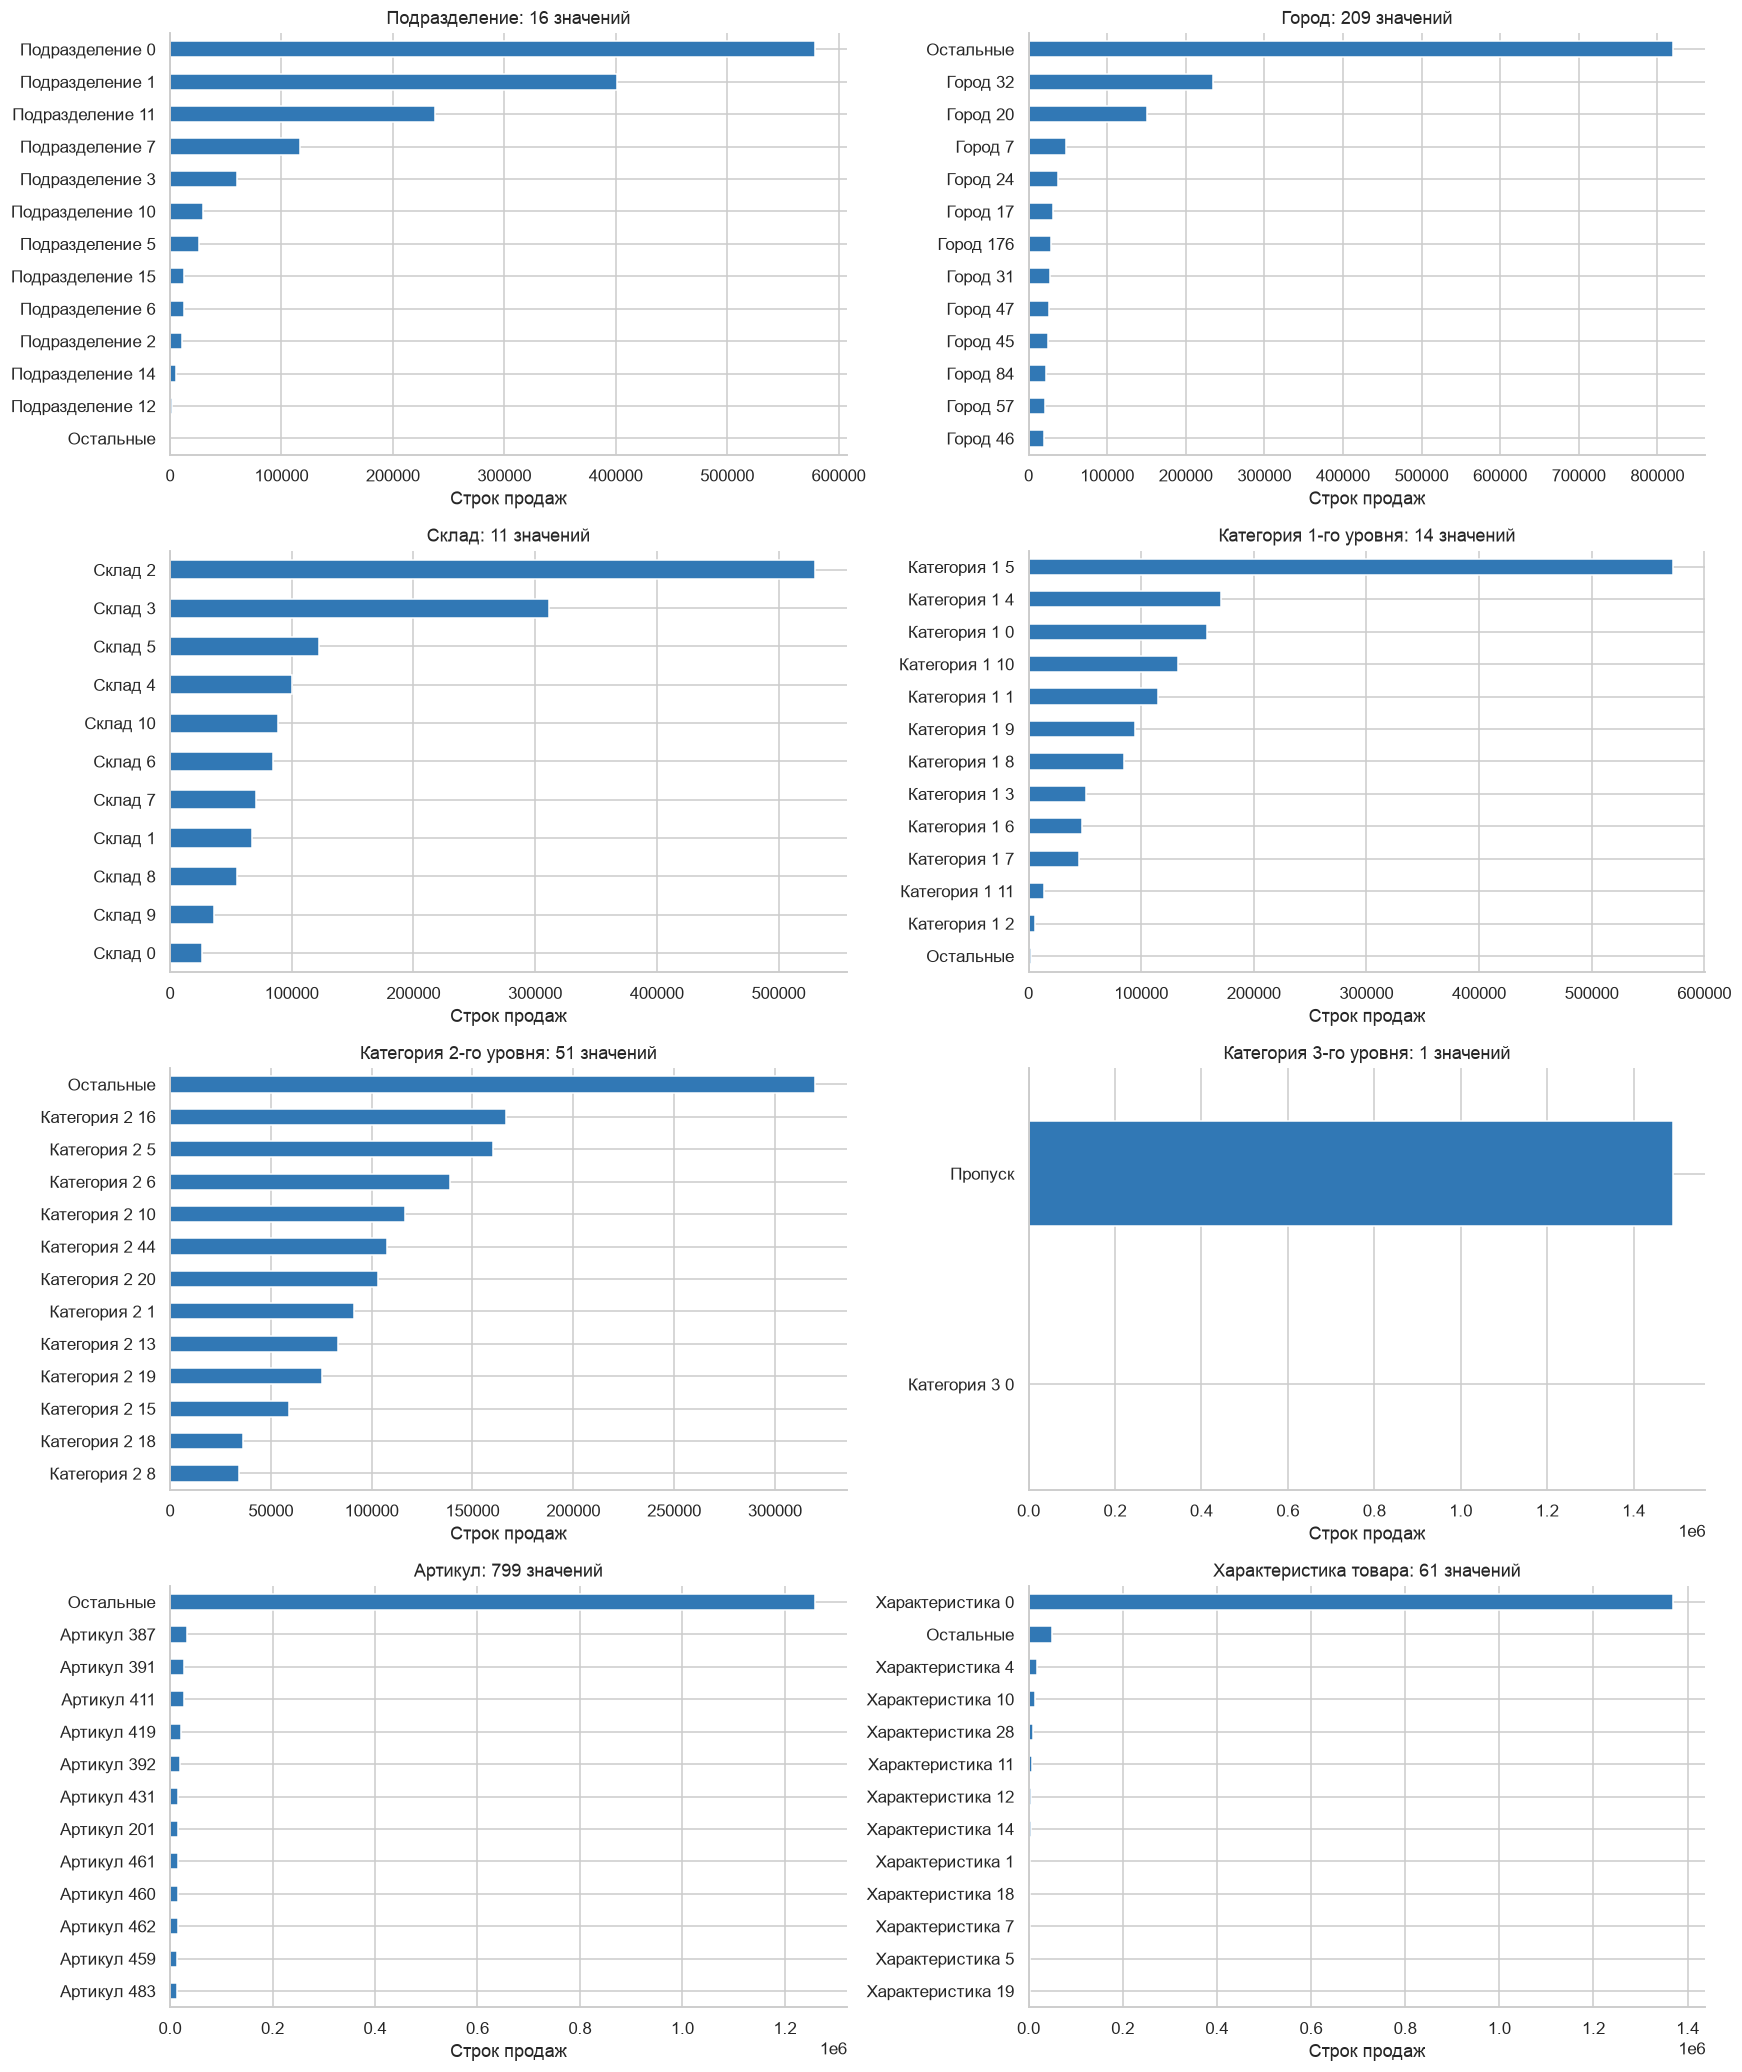

In [5]:
fig,axes=plt.subplots(4,2,figsize=(16,19))
for ax,col in zip(axes.ravel(),CAT):
    vc=sales[col].astype('string').fillna('MISSING').value_counts()
    top=vc.head(12)
    if len(vc)>12: top=pd.concat([top,pd.Series({'OTHER':vc.iloc[12:].sum()})])
    top.rename(index=identifier_label).sort_values().plot.barh(ax=ax,color='#3178b5')
    ax.set(title=f'{feature_label(col)}: {sales[col].nunique()} значений',xlabel='Строк продаж',ylabel='')
plt.tight_layout(); savefig('02_categorical_distributions.png')

## Время и доступность ассортимента

Изменение общего числа продаж может объясняться расширением ассортимента. Сопоставляем количество, число активных пар и средние продажи на пару. Пустые дни в продажах и нулевые остатки — разные события.

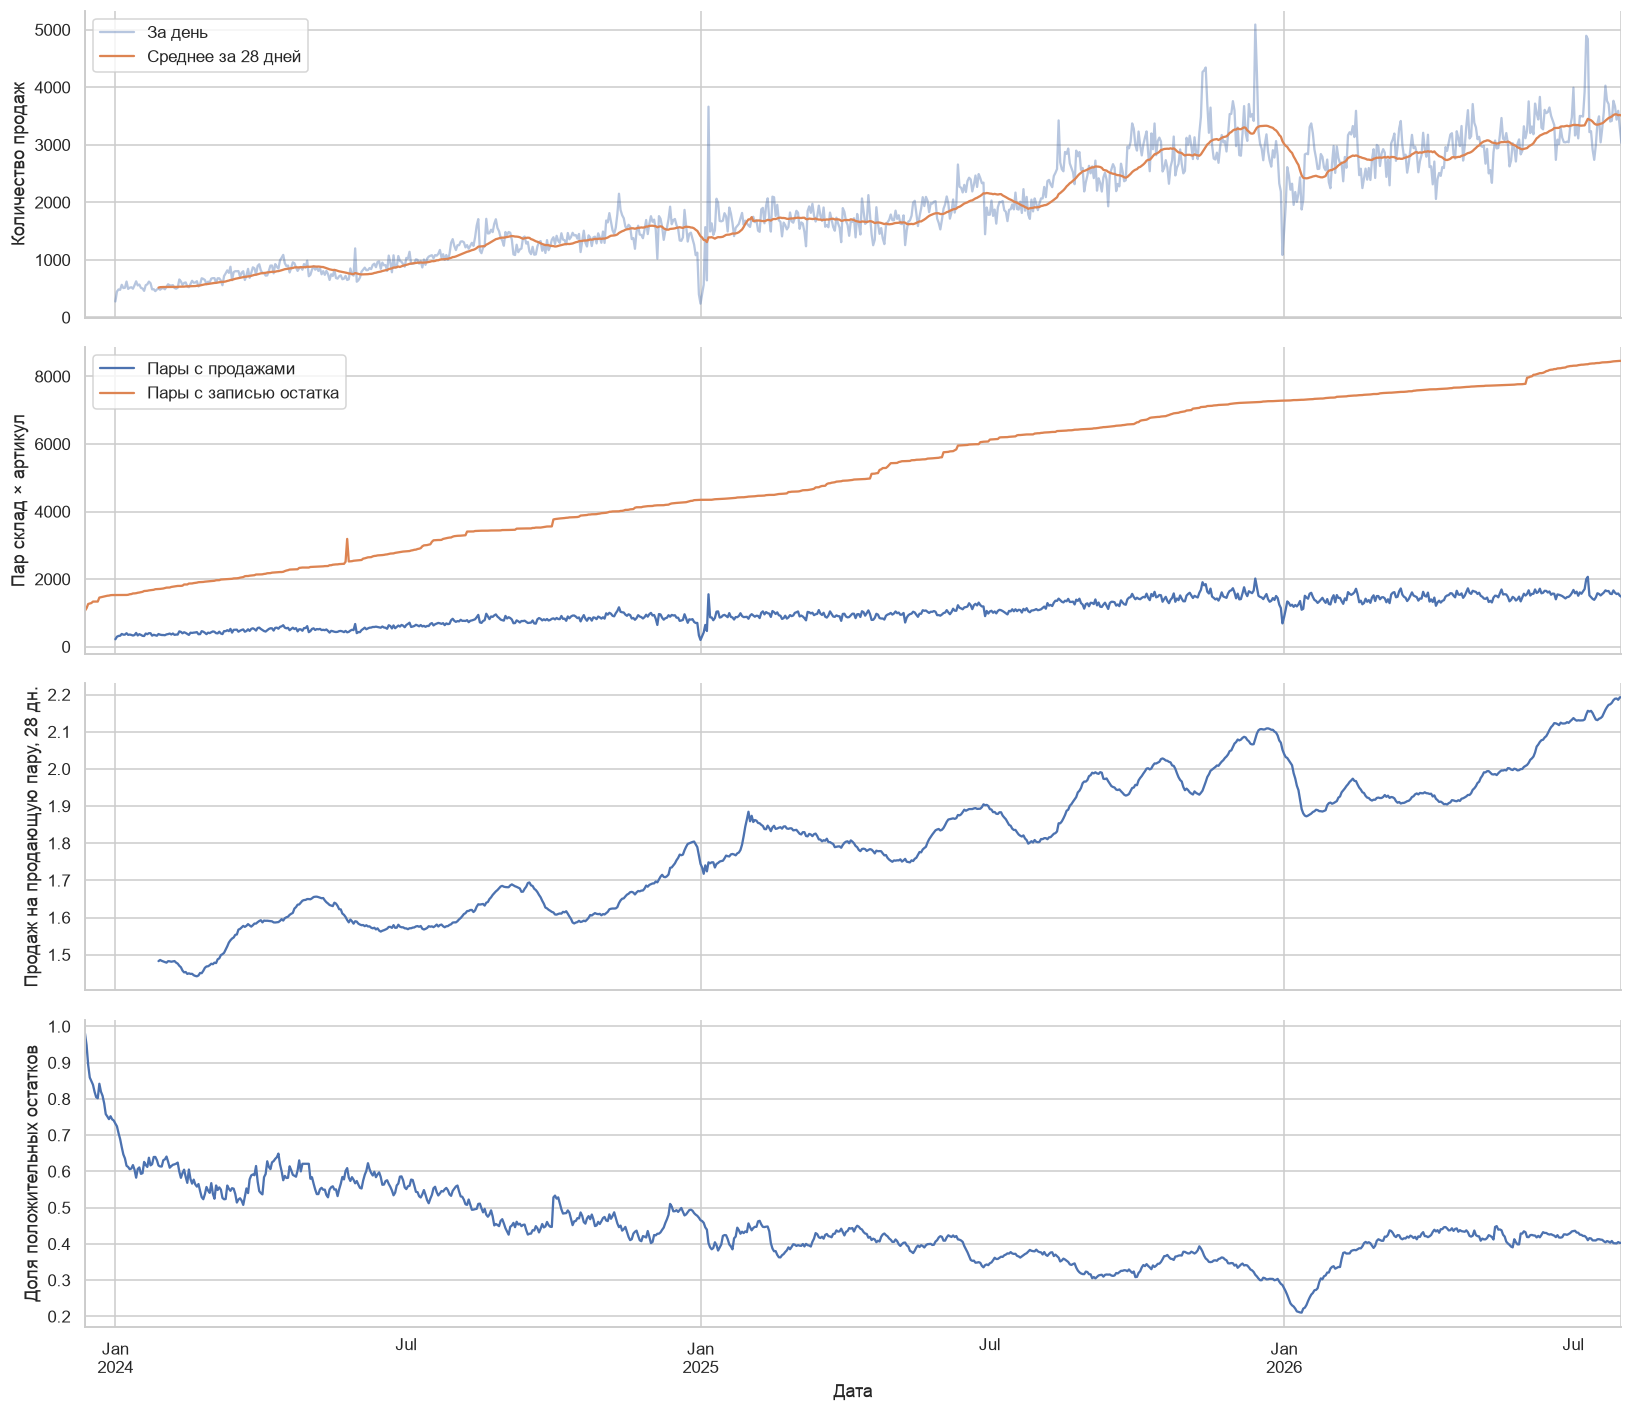

Пропущенных дат внутри диапазона: {'sales': 0, 'stock': 0}


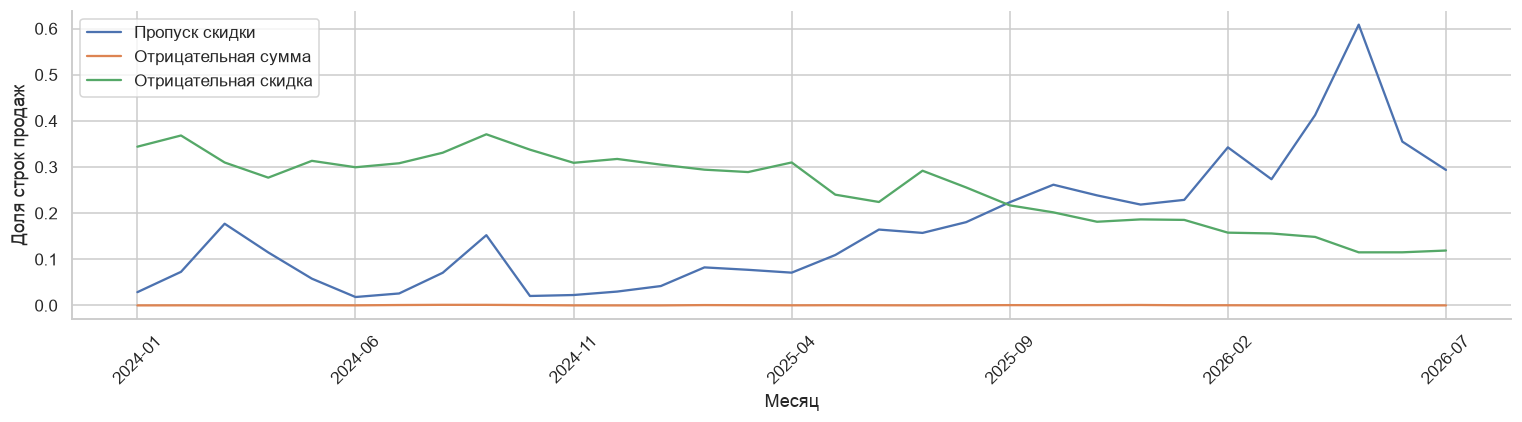

In [6]:
sales_by_date=sales.groupby('date',observed=True).agg(quantity=('quantity','sum'),rows=('quantity','size'))
sales_by_date['selling_pairs']=sales_daily.groupby('date',observed=True).size()
stock_by_date=stock_daily.groupby('date',observed=True).agg(pairs=('stock_mean','size'),positive_pairs=('stock_mean',lambda s:s.gt(0).sum()))
sales_by_date['qty_per_selling_pair']=sales_by_date.quantity/sales_by_date.selling_pairs
fig,axes=plt.subplots(4,1,figsize=(15,13),sharex=True)
sales_by_date.quantity.plot(ax=axes[0],alpha=.4,label='За день'); sales_by_date.quantity.rolling(28).mean().plot(ax=axes[0],label='Среднее за 28 дней'); axes[0].set_ylabel('Количество продаж'); axes[0].legend()
sales_by_date.selling_pairs.plot(ax=axes[1],label='Пары с продажами'); stock_by_date.pairs.plot(ax=axes[1],label='Пары с записью остатка'); axes[1].legend(); axes[1].set_ylabel('Пар склад × артикул')
sales_by_date.qty_per_selling_pair.rolling(28).mean().plot(ax=axes[2]); axes[2].set_ylabel('Продаж на продающую пару, 28 дн.')
(stock_by_date.positive_pairs/stock_by_date.pairs).plot(ax=axes[3]); axes[3].set_ylabel('Доля положительных остатков')
axes[-1].set_xlabel('Дата')
plt.tight_layout(); savefig('03_time_and_coverage.png')
axes[-1].set_xlabel('Дата')
sales_by_date.to_csv(OUT/'daily_sales.csv')
stock_by_date.to_csv(OUT/'daily_stock.csv')
calendar_checks={name:len(pd.date_range(df.date.min(),df.date.max()).difference(df.date.unique())) for name,df in [('sales',sales),('stock',stock)]}
print('Пропущенных дат внутри диапазона:',calendar_checks)
monthly=sales.assign(month=sales.date.dt.to_period('M').astype(str)).groupby('month',observed=True).agg(
    rows=('quantity','size'),discount_missing=('discount_sum',lambda x:x.isna().mean()),
    negative_sales=('sales_sum',lambda x:x.lt(0).mean()),negative_discount=('discount_sum',lambda x:x.lt(0).mean()))
monthly[['discount_missing','negative_sales','negative_discount']].rename(columns={'discount_missing':'Пропуск скидки','negative_sales':'Отрицательная сумма','negative_discount':'Отрицательная скидка'}).plot(figsize=(14,4)); plt.ylabel('Доля строк продаж'); plt.xlabel('Месяц'); plt.xticks(rotation=45); plt.tight_layout(); savefig('04_financial_fields_over_time.png')
monthly.to_csv(OUT/'monthly_quality.csv')

## Сочетания признаков

Здесь сравниваем среднее количество на **записанный день с продажей**: нулевые дни ещё не достроены. Поэтому график описывает структуру продаж, но не является оценкой ежедневного спроса. Полную дневную панель строит следующий ноутбук.

Корреляция Спирмена сравнивает порядок величин: близость к +1 означает совместный рост, к −1 — рост одной величины при уменьшении другой. Она не доказывает причинную связь.

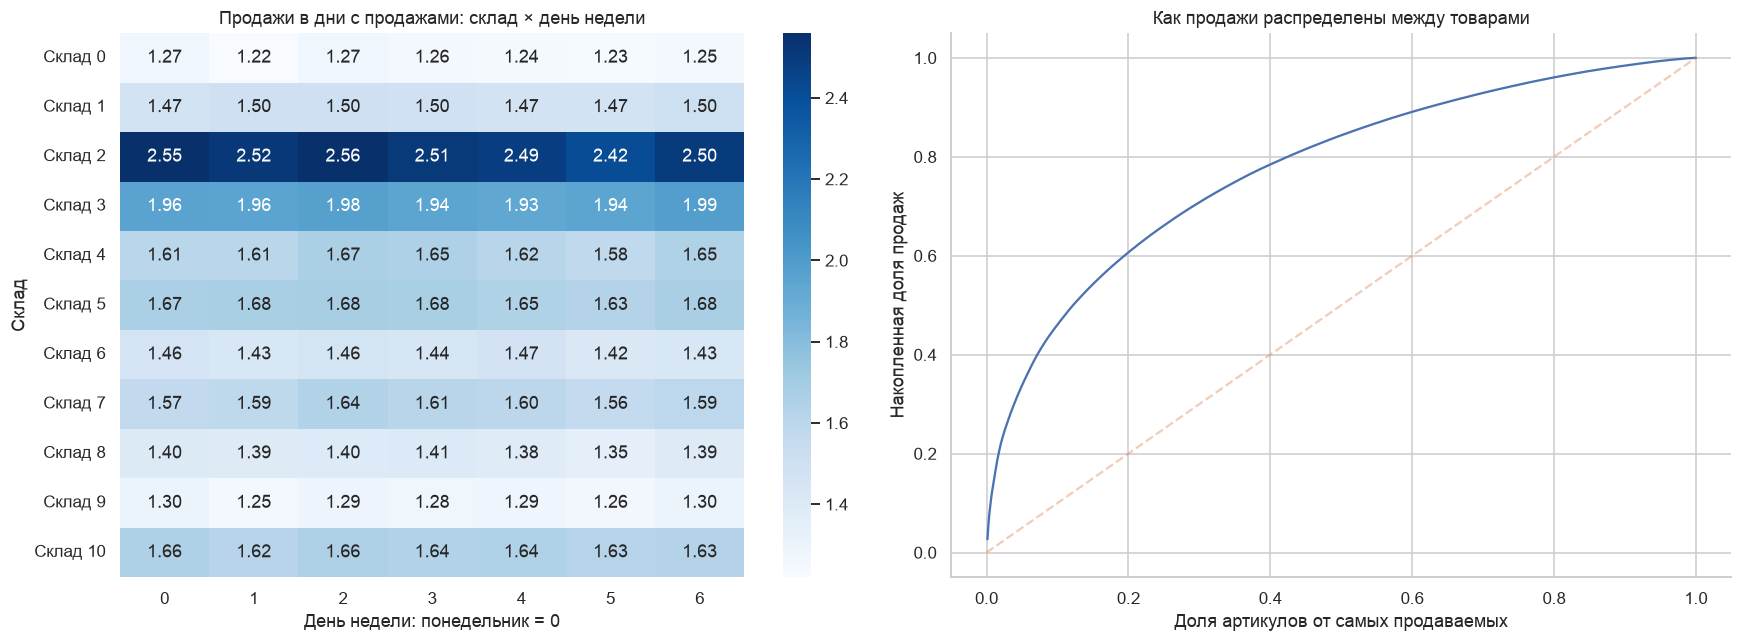

,Значение
Дневных ключей продаж,970677.000000
"Ключей продаж без остатка, %",9.365731
"Ключей с неположительным остатком, %",33.661455


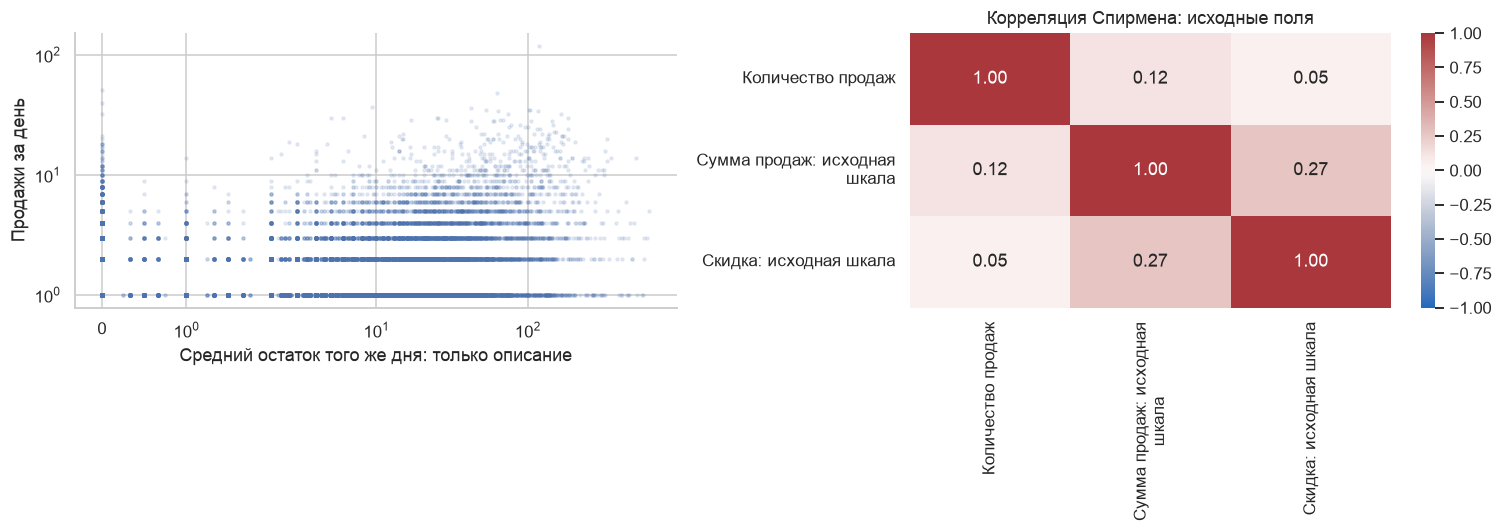

368

In [7]:
interaction=sales_daily.assign(dow=sales_daily.date.dt.dayofweek).pivot_table(index='warehouse_name',columns='dow',values='quantity',aggfunc='mean',observed=True)
fig,axes=plt.subplots(1,2,figsize=(16,6))
sns.heatmap(interaction.rename(index=identifier_label),annot=True,fmt='.2f',cmap='Blues',ax=axes[0]); axes[0].set(ylabel='Склад',title='Продажи в дни с продажами: склад × день недели',xlabel='День недели: понедельник = 0')
article_volume=sales.groupby('article',observed=True).quantity.sum().sort_values(ascending=False)
axes[1].plot(np.arange(1,len(article_volume)+1)/len(article_volume),article_volume.cumsum()/article_volume.sum())
axes[1].plot([0,1],[0,1],'--',alpha=.4); axes[1].set(title='Как продажи распределены между товарами',xlabel='Доля артикулов от самых продаваемых',ylabel='Накопленная доля продаж')
plt.tight_layout(); savefig('05_interactions_and_concentration.png')
joined=sales_daily.merge(stock_daily,on=KEY,how='left',validate='one_to_one')
coverage={'sales_daily_keys':len(joined),'sales_keys_without_stock_pct':float(100*joined.stock_mean.isna().mean()),
          'sales_keys_with_nonpositive_stock_pct':float(100*joined.stock_mean.le(0).mean()),
          'stock_conflicts':conflict_summary,'missing_dates':calendar_checks}
display_ru(pd.Series({k:v for k,v in coverage.items() if not isinstance(v,dict)},name='value'))
example=joined.sample(min(30000,len(joined)),random_state=SEED)
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].scatter(example.stock_mean,example.quantity,s=4,alpha=.12); axes[0].set(xscale='symlog',yscale='log',xlabel='Средний остаток того же дня: только описание',ylabel='Продажи за день')
num=sales[['quantity','sales_sum','discount_sum']].corr(method='spearman')
sns.heatmap(num.rename(index=lambda c:feature_label(c,width=22),columns=lambda c:feature_label(c,width=22)),annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='vlag',ax=axes[1]); axes[1].set_title('Корреляция Спирмена: исходные поля')
plt.tight_layout(); savefig('06_stock_relation_and_correlation.png')
(OUT/'quality_summary.json').write_text(json.dumps(coverage,indent=2))

## Что следует из проверки

- Продажи агрегируем суммой количества на день × склад × артикул. Город и подразделение не однозначно определяются складом, поэтому при этой цели не включаем их как статические признаки.
- Остатки содержат разные значения на одном ключе. В baseline берём среднее, минимум, максимум и число записей, сдвинутые на день. Это рабочее допущение до уточнения источника.
- `category_lvl_3` почти целиком пустой. Отрицательные и дробные денежные поля требуют описания преобразований; цену и долю скидки из них пока не считаем.
- Пары появляются в разные даты. Достраиваем дни только после первого наблюдения пары, чтобы не создавать искусственную историю до появления товара.
- Прогноз следующего дня по фактически известной истории — предварительная постановка. Официальные целевая метрика, горизонт и доступность остатков ещё не предоставлены.